In [1]:
%load_ext autoreload
%autoreload 2

# Broad-scale characteristics of the potential prognostic predictability
This notebook plots figures of the primary predictability characteristics of ESM4, mirroring the first few figures in Frolicher et al. (2020). These will include equivalent calculations in ESM2M.
- [x] Global average PPP for key variables
- [x] Predictability time horizon for key variables
- [x] Zonal mean PPP as a function of lead time

In [4]:
import esm4ppe
import matplotlib.pyplot as plt
import matplotlib as mpl
from dask.diagnostics import ProgressBar
import xarray as xr
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from xhistogram.xarray import histogram
from functions import *

In [14]:
threshold = 0.235559205
colors_v = {'intpp':'tab:green',
            'tos':'tab:blue',
            'MLD_003':'tab:orange'}

## Basic movie of PPP

In [124]:
from xmovie import Movie

ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month').sel(month=1).squeeze()
grid = esm4ppe.open_static('tos','monthly')
variable = 'intpp'

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [128]:
da = ds['intpp'].rename({'lead':'time'}).isel(time=slice(0,36))
mov = Movie(da,vmin=0,vmax=1)
mov.save('mov.ppp-global.gif',framerate=5,overwrite_existing=True)

Movie created at mov.ppp-global.mp4
GIF created at mov.ppp-global.gif


## Global mean PPP

In [15]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')

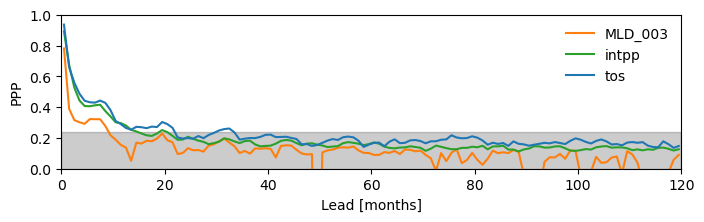

In [21]:
region = 'global'
initmonth=1
fig,ax = plt.subplots(figsize=(8,2))
for name,da in ds.items():
    color= colors_v[name]
    ax.plot(ds['lead']-0.5, da.sel(month=initmonth,region=region),color=color,label=name)
ax.set_ylim([0,1])
ax.set_xlim([0,120])
ax.fill_between([0,120],threshold,color='k',alpha=0.2,zorder=0)
ax.set_ylabel('PPP')
ax.set_xlabel('Lead [months]')
# ax.axhline(threshold,color='k',linestyle='-',linewidth=3,alpha=0.2,zorder=0)
plt.legend(frameon=False)
save_fig(fig,'fig.ppp-global.mean-'+region)

## Time horizon

In [31]:
ds = esm4ppe.open_verify('ocean','monthly',metric='ppp',groupby='month')
grid = esm4ppe.open_static('tos','monthly')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [34]:
initmonth = 1
threshold = 0.235559205
smooth = 12
variable = 'intpp'
da = ds[variable].sel(month=initmonth)
th = calc_timehorizon(da,threshold,dim='lead',smooth=smooth)
with ProgressBar():
    th = th.compute()

[########################################] | 100% Completed | 2.12 sms


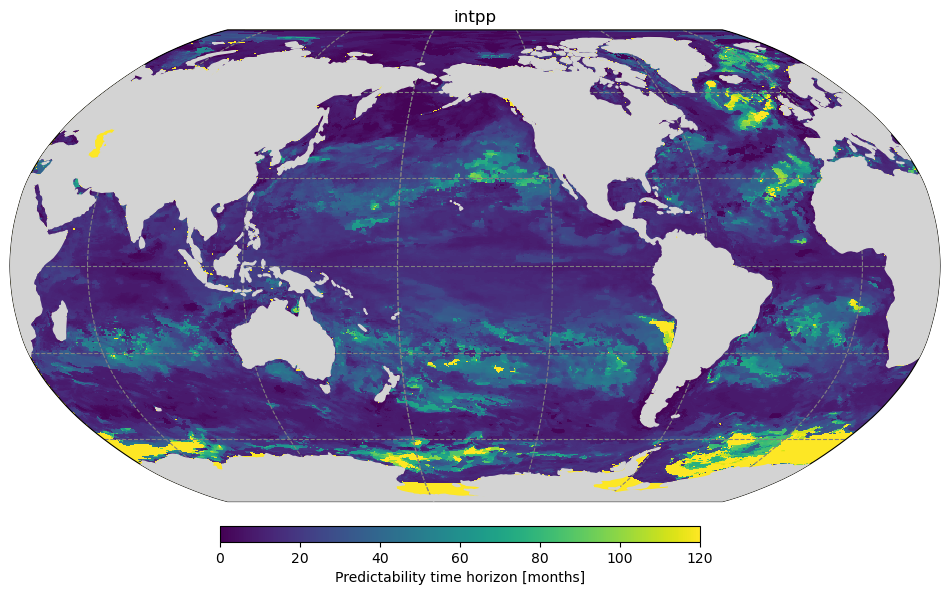

In [35]:
fig,ax = plt.subplots(figsize=(12,8),
                      subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})
im = ax.pcolormesh(grid['geolon'],grid['geolat'],th,transform=ccrs.PlateCarree())
im.set_clim([0,120])
ax.gridlines(color='gray',linestyle='dashed')
ax.add_feature(cfeature.LAND,color='lightgrey',zorder=10)
ax.set_title(variable)
axcb,imcb = add_colorbar(fig,im,[0.3,0.15,0.4,0.02],tick_position='bottom')
imcb.set_label('Predictability time horizon [months]')
save_fig(fig,'fig.ppp-global.timehorizon.'+variable)

### Zonal mean PPP

In [36]:
masks = esm4ppe.get_masks('basin',grid)

In [37]:
weights = grid['areacello']
geolat = grid['geolat']

firstdy = (grid['yq'].values[0]-grid['yh'].values[0])
lat_bins = np.append(grid['yh'].values[0]-firstdy,grid['yq'].values)

In [65]:
variable = 'intpp'
masknames_global = ['global','atlantic_global','pacific_global','indian_global']
da = ds[variable]
lonmean = xr.Dataset()
for maskname in masknames_global:
    mask = masks[maskname]
    lonmean[maskname] = calc_zonalmean(da,mask,weights,geolat,lat_bins)

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/core/indexing.py:1446: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [66]:
with ProgressBar():
    lonmean = lonmean.compute()

[###################                     ] | 47% Completed | 3.63 s ms

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[########################################] | 100% Completed | 9.11 s


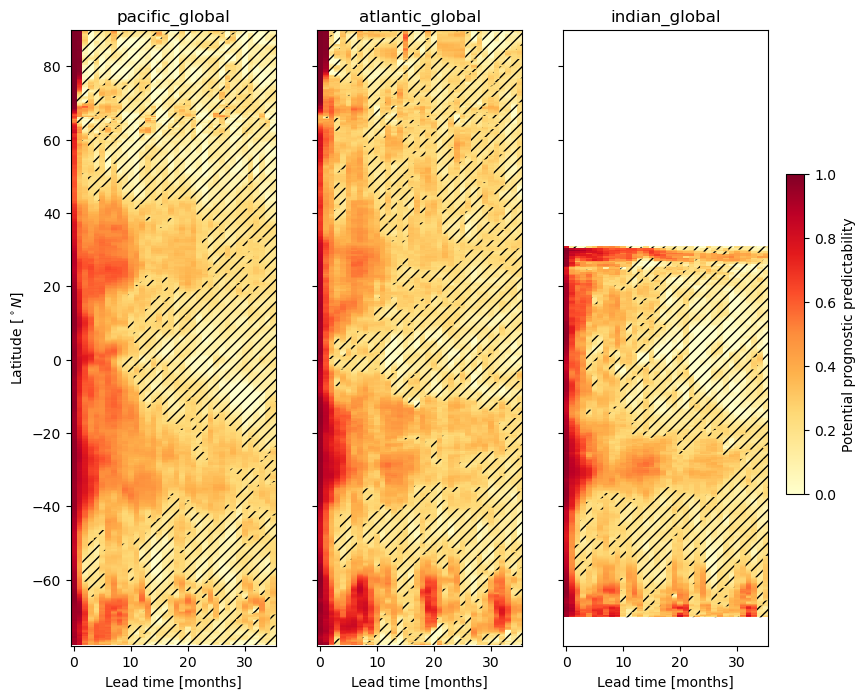

In [67]:
regions = ['pacific_global','atlantic_global','indian_global']
fig,ax = plt.subplots(figsize=(3*len(regions),8),ncols=len(regions))
kwargs = {'cmap':'YlOrRd','vmin':0,'vmax':1}
for i,region in enumerate(regions):
    axnow = ax[i]
    axnow,im = draw_zonalmeans(axnow,lonmean[region].sel(month=1),threshold,**kwargs);
    if i>0:
        axnow.set_yticklabels([])
        axnow.set_ylabel(' ')
    axnow.set_title(region)

axcb,imcb = add_colorbar(fig,im,[0.92,0.3,0.02,0.4],orientation='vertical')
imcb.set_label('Potential prognostic predictability')

save_fig(fig,'fig.ppp-global.lonmean.'+variable)